In [1]:
from pathlib import Path
import time

import faiss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [21]:
current_path = Path.cwd()
project_root = current_path.parent

processed_data_dir = project_root / "data" / "processed"

metadata_path = (
    processed_data_dir
    / "selected_product_metadata.csv"
)

embeddings_path = (
    processed_data_dir
    / "product_embeddings.npy"
)

faiss_index_path = (
    processed_data_dir
    / "product_faiss_hnsw_index.index"
)

In [22]:
product_metadata = pd.read_csv(
    metadata_path
)

product_embeddings = np.load(
    embeddings_path
).astype(
    np.float32,
    copy=False
)

loaded_faiss_index = faiss.read_index(
    str(faiss_index_path)
)

loaded_faiss_index.hnsw.efSearch = 64

assert (
    len(product_metadata)
    == product_embeddings.shape[0]
    == loaded_faiss_index.ntotal
), "Metadata, embeddings and FAISS index sizes do not match."

assert (
    product_embeddings.shape[1]
    == loaded_faiss_index.d
), "Embedding and FAISS dimensions do not match."

print("Metadata shape:", product_metadata.shape)
print("Embeddings shape:", product_embeddings.shape)
print(
    "FAISS index:",
    loaded_faiss_index.ntotal,
    "vectors with",
    loaded_faiss_index.d,
    "dimensions"
)

Metadata shape: (3095, 12)
Embeddings shape: (3095, 1280)
FAISS index: 3095 vectors with 1280 dimensions


In [23]:
embedding_norms = np.linalg.norm(
    product_embeddings,
    axis=1,
    keepdims=True
)

normalised_embeddings = (
    product_embeddings
    / np.clip(
        embedding_norms,
        1e-12,
        None
    )
)

print(
    "Normalised embeddings ready:",
    normalised_embeddings.shape
)

Normalised embeddings ready: (3095, 1280)


In [30]:
def calculate_category_precision_recall_at_k(
    query_index,
    faiss_index,
    normalised_embeddings,
    product_metadata,
    top_k=3
):
    query_embedding = normalised_embeddings[
        query_index:query_index + 1
    ]

    _, neighbour_indices = faiss_index.search(
        query_embedding,
        top_k + 1
    )

    retrieved_indices = [
        int(index)
        for index in neighbour_indices[0]
        if int(index) != query_index
    ][:top_k]

    query_category = product_metadata.iloc[
        query_index
    ]["category_name"]

    retrieved_categories = product_metadata.iloc[
        retrieved_indices
    ]["category_name"]

    relevant_retrieved = (
        retrieved_categories == query_category
    ).sum()

    total_relevant = (
        product_metadata["category_name"]
        == query_category
    ).sum() - 1

    precision_at_k = (
        relevant_retrieved / top_k
    )

    recall_at_k = (
        relevant_retrieved / total_relevant
        if total_relevant > 0
        else 0
    )

    return precision_at_k, recall_at_k

In [31]:
category_evaluation_results = []

top_k = 3

for query_index in range(len(product_metadata)):

    category_precision_at_3, category_recall_at_3 = (
        calculate_category_precision_recall_at_k(
            query_index=query_index,
            faiss_index=loaded_faiss_index,
            normalised_embeddings=normalised_embeddings,
            product_metadata=product_metadata,
            top_k=top_k
        )
    )

    query_row = product_metadata.iloc[
        query_index
    ]

    category_evaluation_results.append(
        {
            "query_index": query_index,
            "image_id": query_row["image_id"],
            "class_id": query_row["class_id"],
            "category_name": query_row["category_name"],
            "category_precision_at_3": category_precision_at_3,
            "category_recall_at_3": category_recall_at_3
        }
    )

category_evaluation_at_3_df = pd.DataFrame(
    category_evaluation_results
)

print(
    "Category evaluation shape:",
    category_evaluation_at_3_df.shape
)

Category evaluation shape: (3095, 6)


In [34]:
average_category_precision_at_3 = (
    category_evaluation_at_3_df[
        "category_precision_at_3"
    ].mean()
)

average_category_recall_at_3 = (
    category_evaluation_at_3_df[
        "category_recall_at_3"
    ].mean()
)

print(
    "Baseline Category Precision@3:",
    average_category_precision_at_3
)

print(
    "Baseline Category Recall@3:",
    average_category_recall_at_3
)

Baseline Category Precision@3: 0.8597738287560581
Baseline Category Recall@3: 0.010040522109452483


In [33]:
category_performance_df = (
    category_evaluation_at_3_df
    .groupby("category_name")
    .agg(
        number_of_queries=(
            "query_index",
            "count"
        ),
        average_category_precision_at_3=(
            "category_precision_at_3",
            "mean"
        ),
        average_category_recall_at_3=(
            "category_recall_at_3",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        by="average_category_precision_at_3",
        ascending=False
    )
)

category_performance_df

,category_name,number_of_queries,average_category_precision_at_3,average_category_recall_at_3
0,bicycle,250,0.958667,0.011550
7,mug,264,0.940657,0.010730
8,sofa,260,0.926923,0.010737
1,cabinet,265,0.884277,0.010049
9,stapler,263,0.883397,0.010115
4,fan,244,0.852459,0.010524
11,toaster,246,0.833333,0.010204
10,table,259,0.823681,0.009578
3,coffee_maker,260,0.821795,0.009519
5,kettle,259,0.819820,0.009533


In [35]:
def calculate_exact_product_precision_recall_at_k(
    query_index,
    faiss_index,
    normalised_embeddings,
    product_metadata,
    top_k=3
):
    query_embedding = normalised_embeddings[
        query_index:query_index + 1
    ]

    _, neighbour_indices = faiss_index.search(
        query_embedding,
        top_k + 1
    )

    retrieved_indices = [
        int(index)
        for index in neighbour_indices[0]
        if int(index) != query_index
    ][:top_k]

    query_class_id = product_metadata.iloc[
        query_index
    ]["class_id"]

    retrieved_class_ids = product_metadata.iloc[
        retrieved_indices
    ]["class_id"]

    relevant_retrieved = (
        retrieved_class_ids == query_class_id
    ).sum()

    total_relevant = (
        product_metadata["class_id"]
        == query_class_id
    ).sum() - 1

    precision_at_k = relevant_retrieved / top_k

    recall_at_k = (
        relevant_retrieved / total_relevant
        if total_relevant > 0
        else 0
    )

    return precision_at_k, recall_at_k

In [36]:
exact_product_evaluation_results = []

top_k = 3

for query_index in range(len(product_metadata)):

    exact_product_precision_at_3, exact_product_recall_at_3 = (
        calculate_exact_product_precision_recall_at_k(
            query_index=query_index,
            faiss_index=loaded_faiss_index,
            normalised_embeddings=normalised_embeddings,
            product_metadata=product_metadata,
            top_k=top_k
        )
    )

    exact_product_evaluation_results.append(
        {
            "query_index": query_index,
            "exact_product_precision_at_3": (
                exact_product_precision_at_3
            ),
            "exact_product_recall_at_3": (
                exact_product_recall_at_3
            )
        }
    )

exact_product_evaluation_df = pd.DataFrame(
    exact_product_evaluation_results
)

average_exact_product_precision_at_3 = (
    exact_product_evaluation_df[
        "exact_product_precision_at_3"
    ].mean()
)

average_exact_product_recall_at_3 = (
    exact_product_evaluation_df[
        "exact_product_recall_at_3"
    ].mean()
)

print(
    "Baseline Exact-Product Precision@3:",
    average_exact_product_precision_at_3
)

print(
    "Baseline Exact-Product Recall@3:",
    average_exact_product_recall_at_3
)

Baseline Exact-Product Precision@3: 0.5539041464728056
Baseline Exact-Product Recall@3: 0.39649434571890146


In [37]:
def display_baseline_recommendations(
    query_index,
    faiss_index,
    normalised_embeddings,
    product_metadata,
    top_k=3
):
    query_embedding = normalised_embeddings[
        query_index:query_index + 1
    ]

    similarity_scores, neighbour_indices = (
        faiss_index.search(
            query_embedding,
            top_k + 1
        )
    )

    retrieved_results = [
        (int(index), float(score))
        for index, score in zip(
            neighbour_indices[0],
            similarity_scores[0]
        )
        if int(index) != query_index
    ][:top_k]

    query_row = product_metadata.iloc[
        query_index
    ]

    figure, axes = plt.subplots(
        1,
        top_k + 1,
        figsize=(16, 4)
    )

    query_image = Image.open(
        query_row["full_path"]
    ).convert("RGB")

    axes[0].imshow(query_image)
    axes[0].set_title(
        f"Query\n"
        f"Category: {query_row['category_name']}\n"
        f"Class ID: {query_row['class_id']}"
    )
    axes[0].axis("off")

    for rank, (
        retrieved_index,
        similarity_score
    ) in enumerate(
        retrieved_results,
        start=1
    ):
        retrieved_row = product_metadata.iloc[
            retrieved_index
        ]

        retrieved_image = Image.open(
            retrieved_row["full_path"]
        ).convert("RGB")

        axes[rank].imshow(retrieved_image)
        axes[rank].set_title(
            f"Rank {rank}\n"
            f"Category: {retrieved_row['category_name']}\n"
            f"Class ID: {retrieved_row['class_id']}\n"
            f"Score: {similarity_score:.4f}"
        )
        axes[rank].axis("off")

    plt.tight_layout()
    plt.show()

Visual inspection category: bicycle


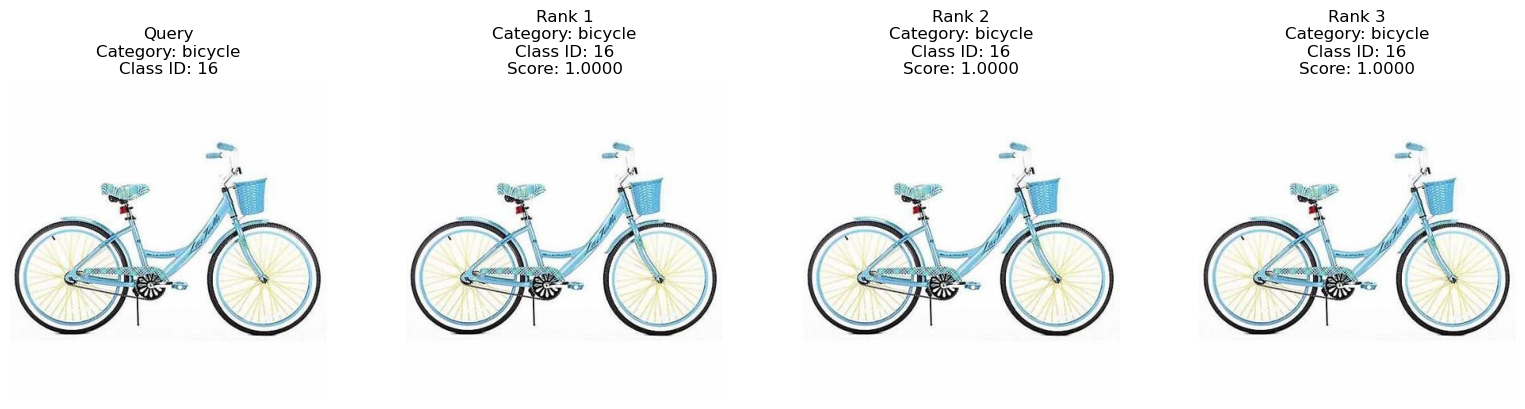

Visual inspection category: coffee_maker


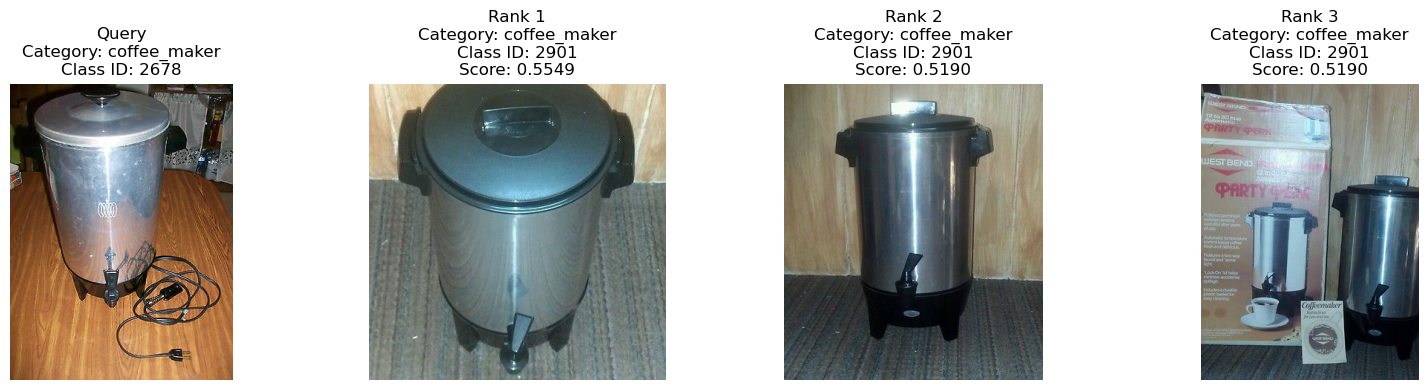

Visual inspection category: lamp


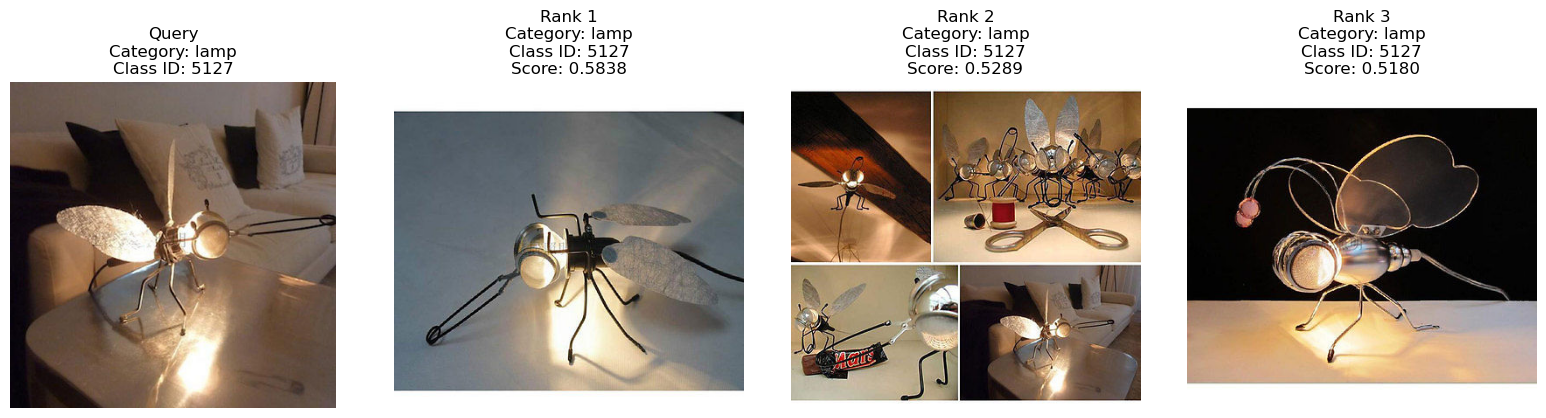

In [38]:
visual_inspection_categories = [
    "bicycle",
    "coffee_maker",
    "lamp"
]

for category_name in visual_inspection_categories:

    query_index = product_metadata.index[
        product_metadata["category_name"]
        == category_name
    ][0]

    print("Visual inspection category:", category_name)

    display_baseline_recommendations(
        query_index=query_index,
        faiss_index=loaded_faiss_index,
        normalised_embeddings=normalised_embeddings,
        product_metadata=product_metadata,
        top_k=3
    )